# Le niveau de vie le long des lignes : les « montagnes »

Ce notebook trace, pour une ligne de métro ou de RER, le profil du niveau de vie des habitants le long de son tracé. Chaque ligne devient une « montagne » : on la parcourt d'un terminus à l'autre et on voit les quartiers riches et pauvres qu'elle traverse.

Il réutilise les fonctions des modules du projet (`pretraitement_donnees.py`, `analyse_donnees.py`, `visualisation_donnees.py`).

In [11]:
import matplotlib.pyplot as plt

from analyse_donnees import (
    ajouter_communes_stations,
    calculer_carreaux_traverses,
    calculer_nv_par_commune,
    calculer_nv_par_station,
    calculer_temps_trajet,
    joindre_carreaux_stations,
    positionner_stations_ligne,
)
from pretraitement_donnees import (
    URL_ZIP_FILOSOFI,
    URL_ZIP_IDFM,
    charger_arrets,
    charger_communes,
    charger_filosofi,
    charger_horaires,
    charger_parcours,
    charger_routes,
    charger_stations,
    charger_trips,
    construire_aretes,
    construire_centres_carreaux,
    construire_graphe_reseau,
    construire_lignes_idfm,
    construire_stations,
    indicateurs_filosofi,
    telecharger_zip,
)
from visualisation_donnees import (
    enregistrer_graphique,
    generer_montagnes_empilees,
    generer_montagnes_population,
)

ImportError: cannot import name 'generer_montagnes_population' from 'visualisation_donnees' (/Users/cabs/python_datascience_liuqi/visualisation_donnees.py)

## 1. Données
NDV, Réseau, Rattachement carreaux

Les données (environ 3,4 Go une fois décompressées) ne sont téléchargées qu'une fois : décommenter les deux lignes ci-dessous au premier lancement.

In [ ]:
# telecharger_zip(URL_ZIP_IDFM, "idfm")
# telecharger_zip(URL_ZIP_FILOSOFI, "filosofi")

### Niveau de vie : Filosofi

Les carreaux de 200 m de l'Insee donnent, pour chaque carreau habité, le nombre d'habitants (`ind`) et la somme de leurs niveaux de vie (`ind_snv`). Nous en déduisons le niveau de vie moyen `nv` de chaque carreau.

In [ ]:
df_filosofi = charger_filosofi("data/filosofi/france_metro/carreaux_200m_met.shp")
df_filosofi = indicateurs_filosofi(df_filosofi)
gpd_centres = construire_centres_carreaux(df_filosofi)

### Réseau : IDFM

Nous gardons les lignes de métro et de RER, leurs tracés et leurs stations.

In [ ]:
df_routes = charger_routes("data/idfm")
df_trips = charger_trips("data/idfm", df_routes)
gpd_idfm = construire_lignes_idfm(charger_parcours("data/idfm", df_trips))

df_arrets = charger_arrets("data/idfm", df_trips)
df_stations = charger_stations("data/idfm", df_arrets)
gpd_stations = construire_stations(df_stations)

### Rattachement des carreaux aux stations

Chaque carreau est rattaché à sa station la plus proche (à moins de 1,5 km). Le calcul des temps de trajet vers Châtelet et La Défense fait partie de ce rattachement, même si les montagnes ne l'utilisent pas.

In [ ]:
df_horaires = charger_horaires("data/idfm", df_trips)
graphe_reseau = construire_graphe_reseau(construire_aretes(df_horaires))
destinations = gpd_stations.loc[
    gpd_stations["stop_name"].isin(["Châtelet - Les Halles", "Châtelet", "La Défense"]),
    "stop_id",
]
df_temps = calculer_temps_trajet(graphe_reseau, destinations)

gpd_carreaux = joindre_carreaux_stations(
    gpd_centres, gpd_stations, df_temps, distance_max=1500, vitesse_marche=75
)

## 2. Indicateurs

- **Autour de chaque station** : niveau de vie moyen des habitants dont c'est la station la plus proche.
- **Par commune** (ou par arrondissement à Paris) : niveau de vie moyen de tous ses habitants.
- **Moyenne de l'Île-de-France** : la référence des montagnes.

Toutes les moyennes sont pondérées par la population (somme des niveaux de vie divisée par le nombre d'habitants), et non des moyennes de carreaux.

In [ ]:
df_nv = calculer_nv_par_station(gpd_carreaux)
nv_moyen = gpd_carreaux["ind_snv"].sum() / gpd_carreaux["ind"].sum()
gpd_communes = charger_communes()
nv_communes = calculer_nv_par_commune(gpd_centres, gpd_communes)
print(f"Niveau de vie moyen en Île-de-France : {nv_moyen:,.0f} € par an".replace(",", " "))

Niveau de vie moyen en Île-de-France : 28 543 € par an


Pour chaque ligne, nous plaçons les stations le long du tracé (en km depuis le terminus ouest, ou nord pour une ligne nord-sud), nous les rattachons à leur commune, et nous relevons tous les carreaux de 200 m que le tracé traverse.

In [ ]:
def preparer_lignes(noms):
    "Stations, couleur et carreaux traversés de chaque ligne"
    lignes = {}
    for nom in noms:
        gpd_ligne = positionner_stations_ligne(gpd_stations, df_stations, gpd_idfm, nom)
        gpd_ligne = ajouter_communes_stations(gpd_ligne, gpd_communes)
        df_carreaux = calculer_carreaux_traverses(df_filosofi, gpd_ligne, gpd_idfm, nom)
        filtre = df_routes["route_short_name"] == nom
        couleur = "#" + df_routes.loc[filtre, "route_color"].iloc[0]
        lignes[nom] = (gpd_ligne, couleur, df_carreaux)
    return lignes

## 3. Les montagnes

**Comment les lire :**

- **Barres** : un carreau de 200 m traversé par la ligne, sur la longueur de tracé qui le traverse. Elles partent de la moyenne de l'Île-de-France (pointillés) : vers le haut et en vert si le carreau est plus riche, vers le bas et en rouge s'il est plus pauvre. Les trous correspondent aux endroits sans habitants (Seine, parcs, bois, aéroports).
- **Courbe de la couleur de la ligne** : niveau de vie autour de chaque station.
- **Traits bleus** : niveau de vie moyen de la commune ou de l'arrondissement.
- **Traits noirs verticaux** : entrée ou sortie de Paris.
- **Plan** : tracé des lignes ; la pastille marque le terminus de départ (0 km).

Toutes les lignes d'une même figure partagent les mêmes échelles (km, niveau de vie, couleurs) : leurs montagnes sont directement comparables.

### 3.1 Métro : lignes 1, 2, 9, 11, 13 et 14

In [ ]:
lignes_metro = preparer_lignes(["1", "2", "9", "11", "13", "14"])
axes = generer_montagnes_empilees(
    lignes_metro, df_nv, nv_moyen, nv_communes, gpd_idfm, gpd_communes
)
enregistrer_graphique(axes[0], "Metros 1, 2 9, 11, 13 et 14 : montagnes_empilees")
plt.show()

### 3.2 Nombre d'habitants par station

Même tracé, mais la hauteur est maintenant le **nombre d'habitants rattachés à chaque station** : ceux dont c'est la station de métro ou de RER la plus proche, à moins de 1,5 km. La ligne pointillée est la moyenne sur toutes les stations de métro et de RER.

Ce nombre dépend de deux choses : la densité de population autour de la station, et l'écart avec les stations voisines. Dans Paris, les stations sont si proches que chacune ne récupère que quelques centaines à quelques milliers d'habitants ; en banlieue, une gare isolée en récupère des dizaines de milliers.

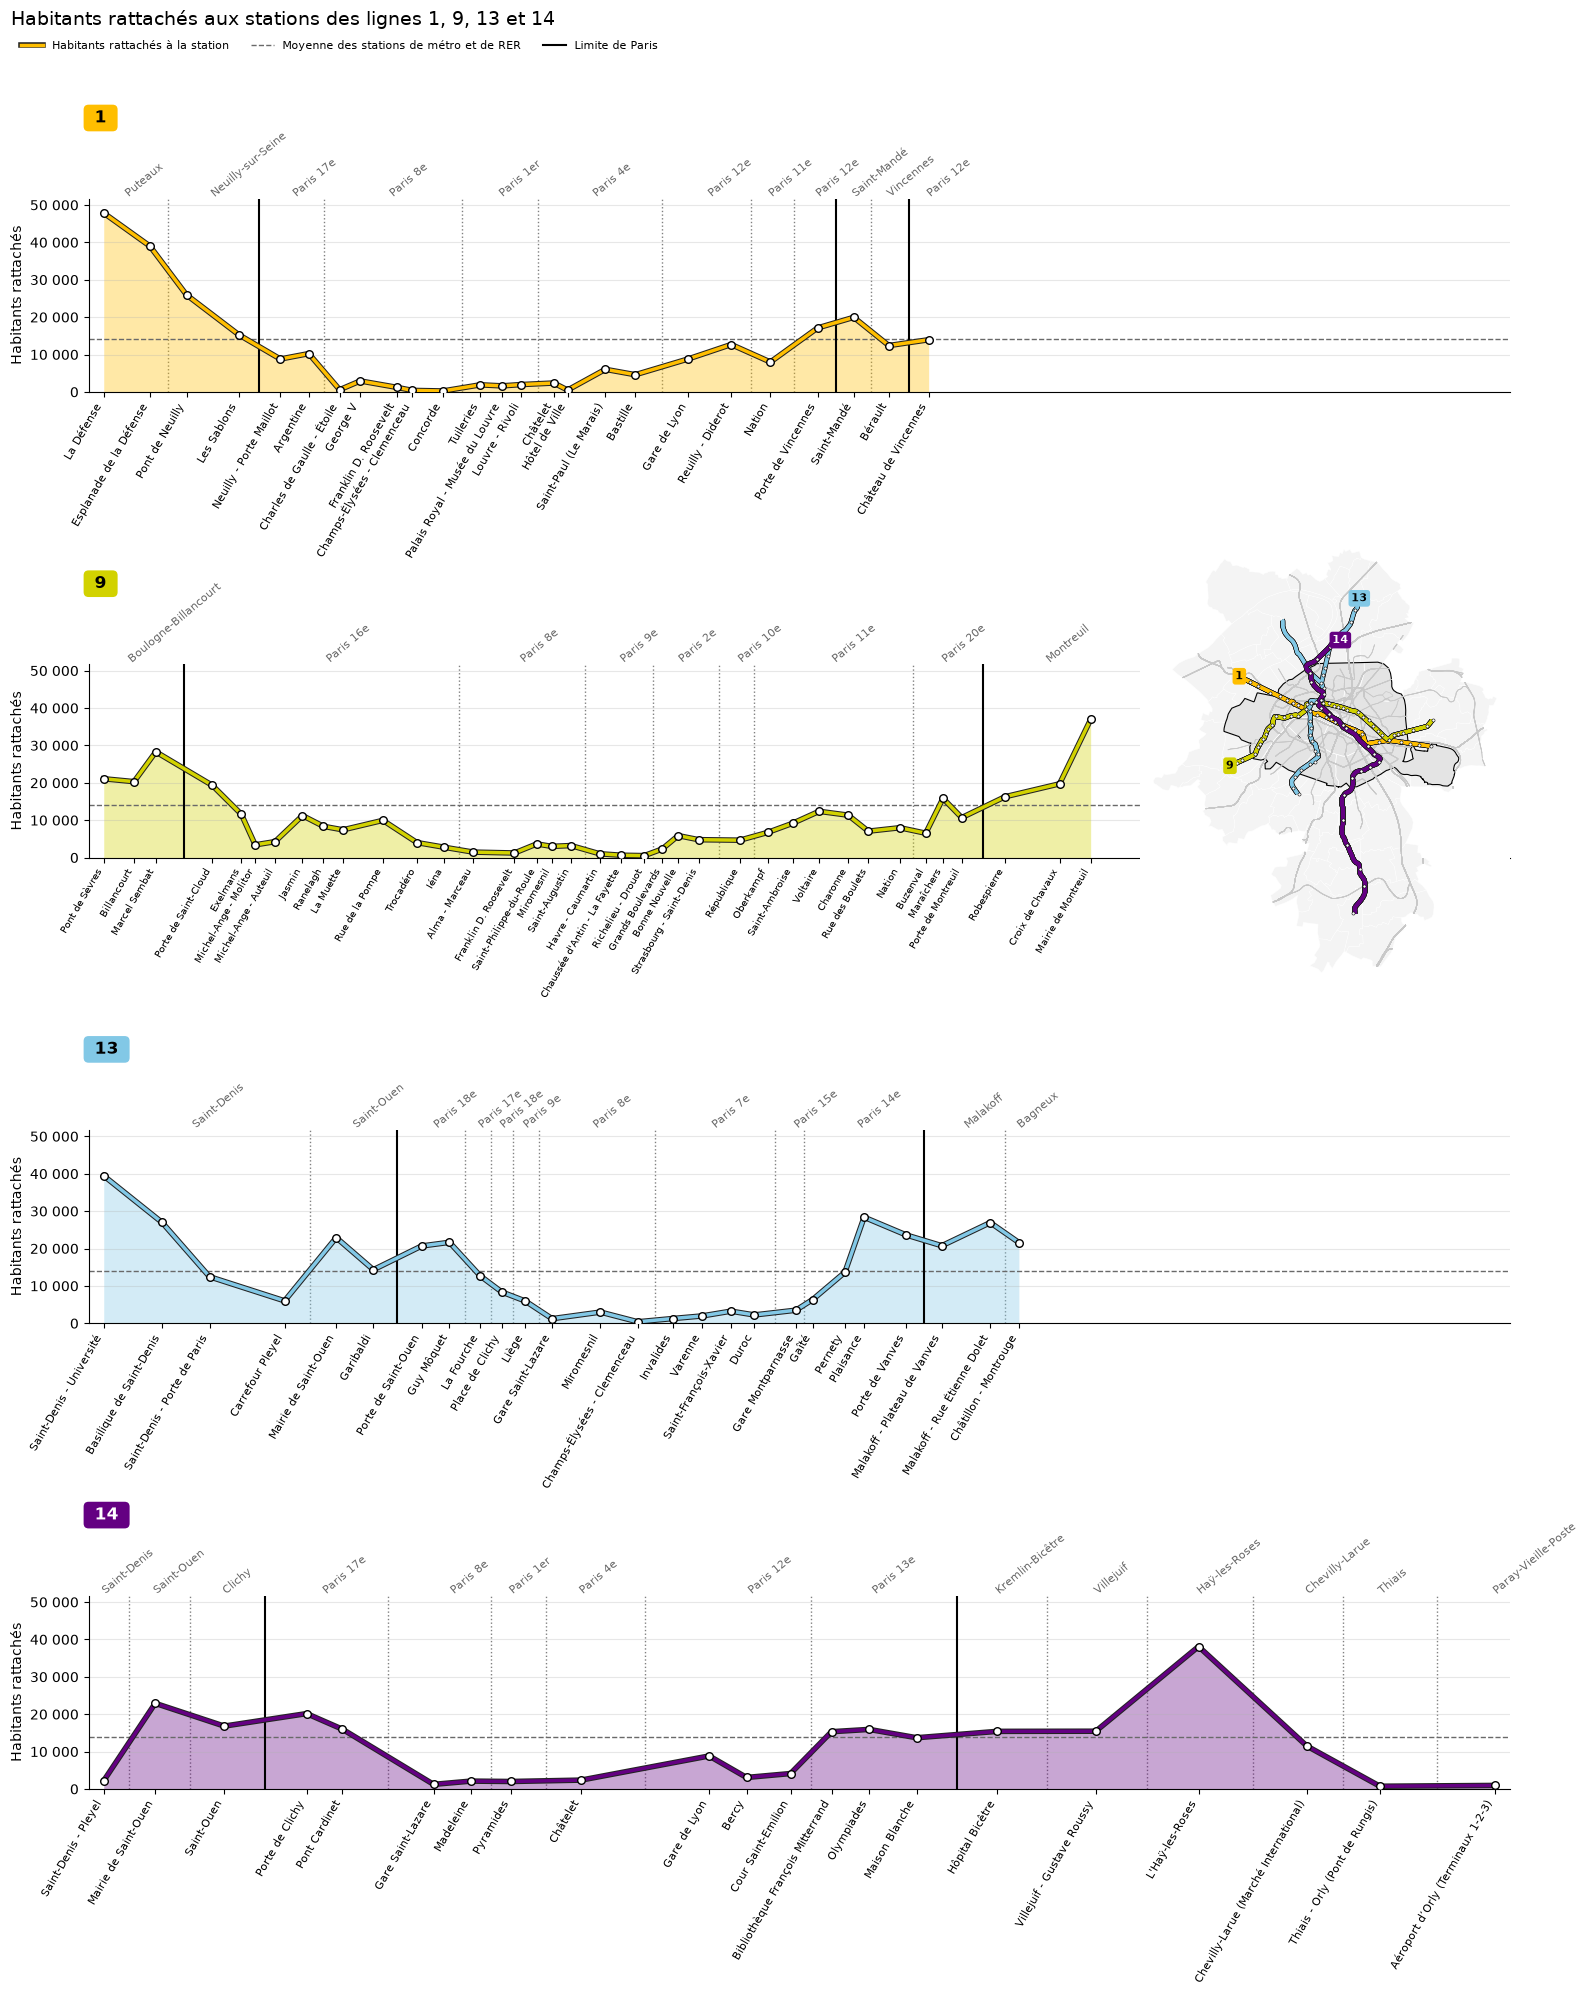

In [ ]:
axes = generer_montagnes_population(lignes_metro, df_nv, gpd_idfm, gpd_communes)
enregistrer_graphique(axes[0], "Metros 1, 2, 9, 11, 13 et 14 : habitants par station")
plt.show()

### 3.3 RER : lignes A et B

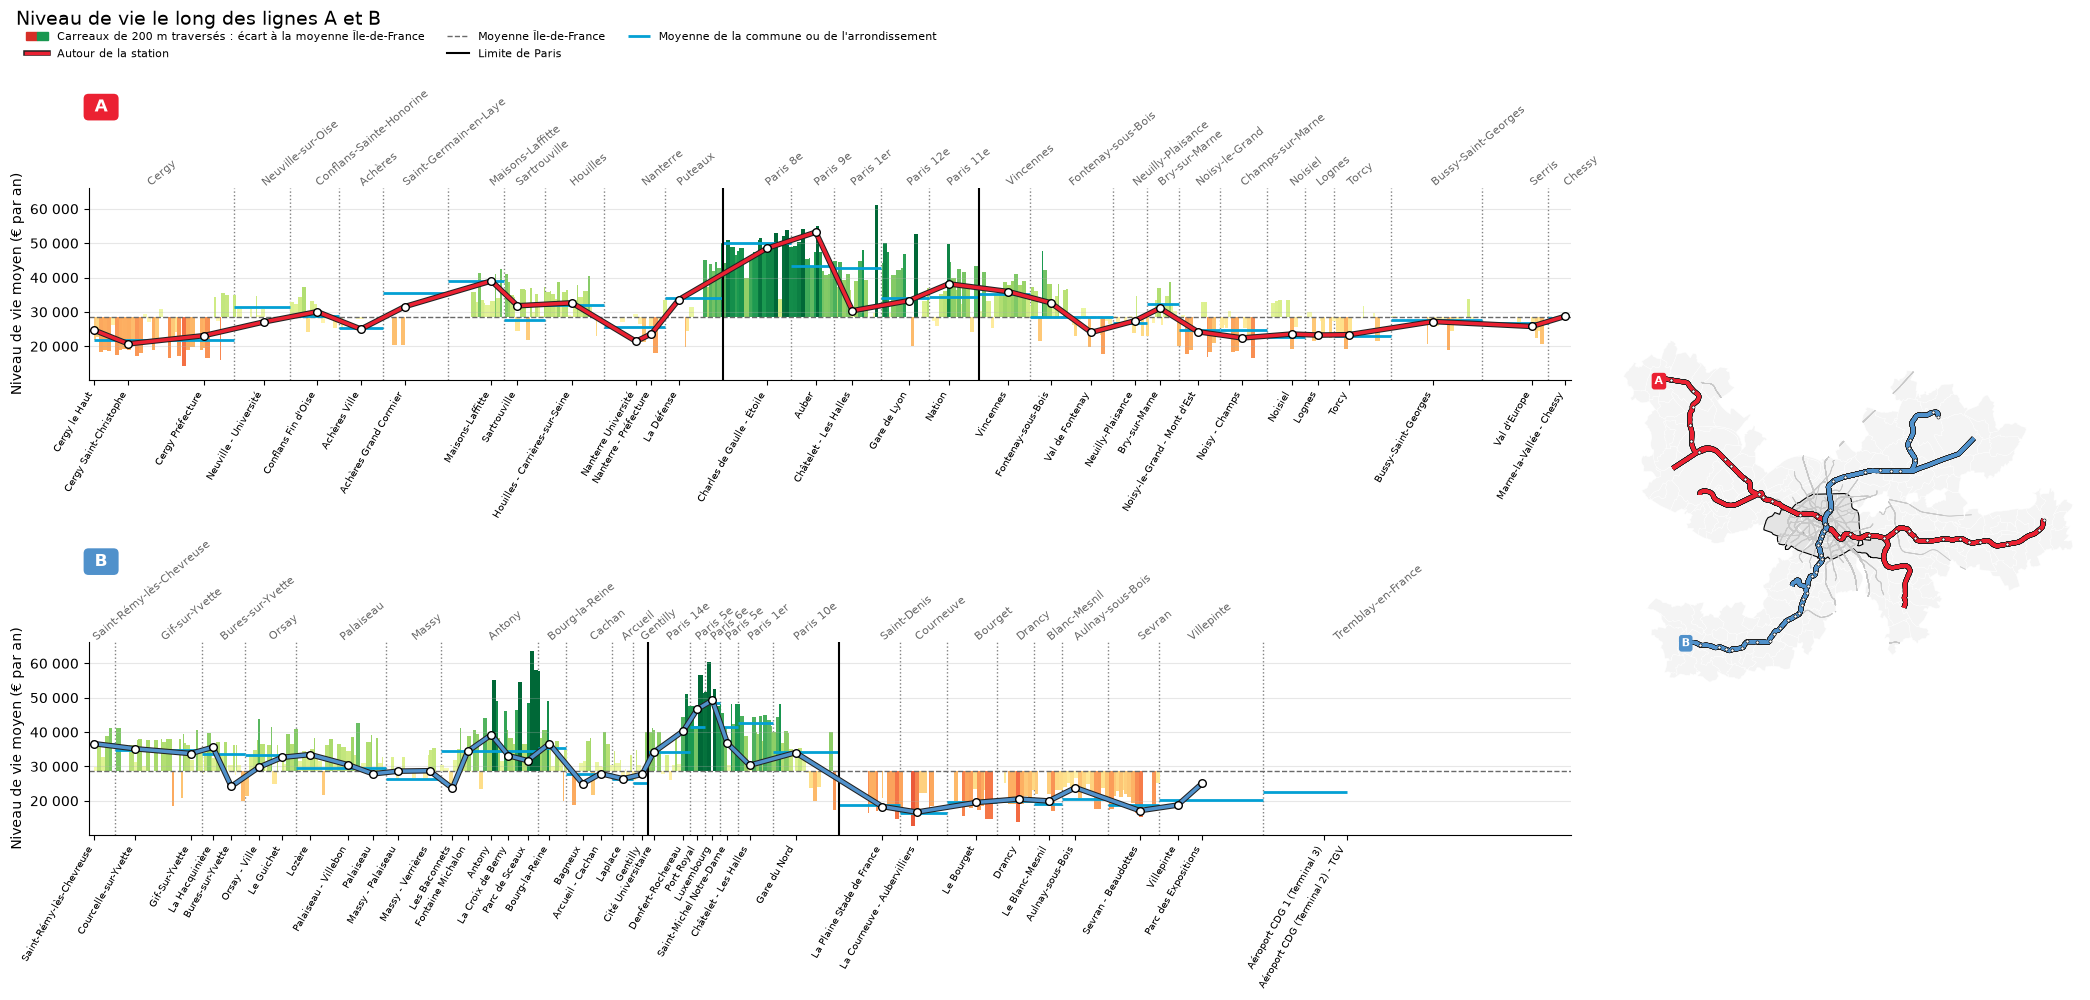

In [ ]:
lignes_rer = preparer_lignes(["A", "B"])
axes = generer_montagnes_empilees(
    lignes_rer, df_nv, nv_moyen, nv_communes, gpd_idfm, gpd_communes
)
enregistrer_graphique(axes[0], "RER A et B : montagnes_empilees")
plt.show()

### 3.4 Nombre d'habitants par station (RER)

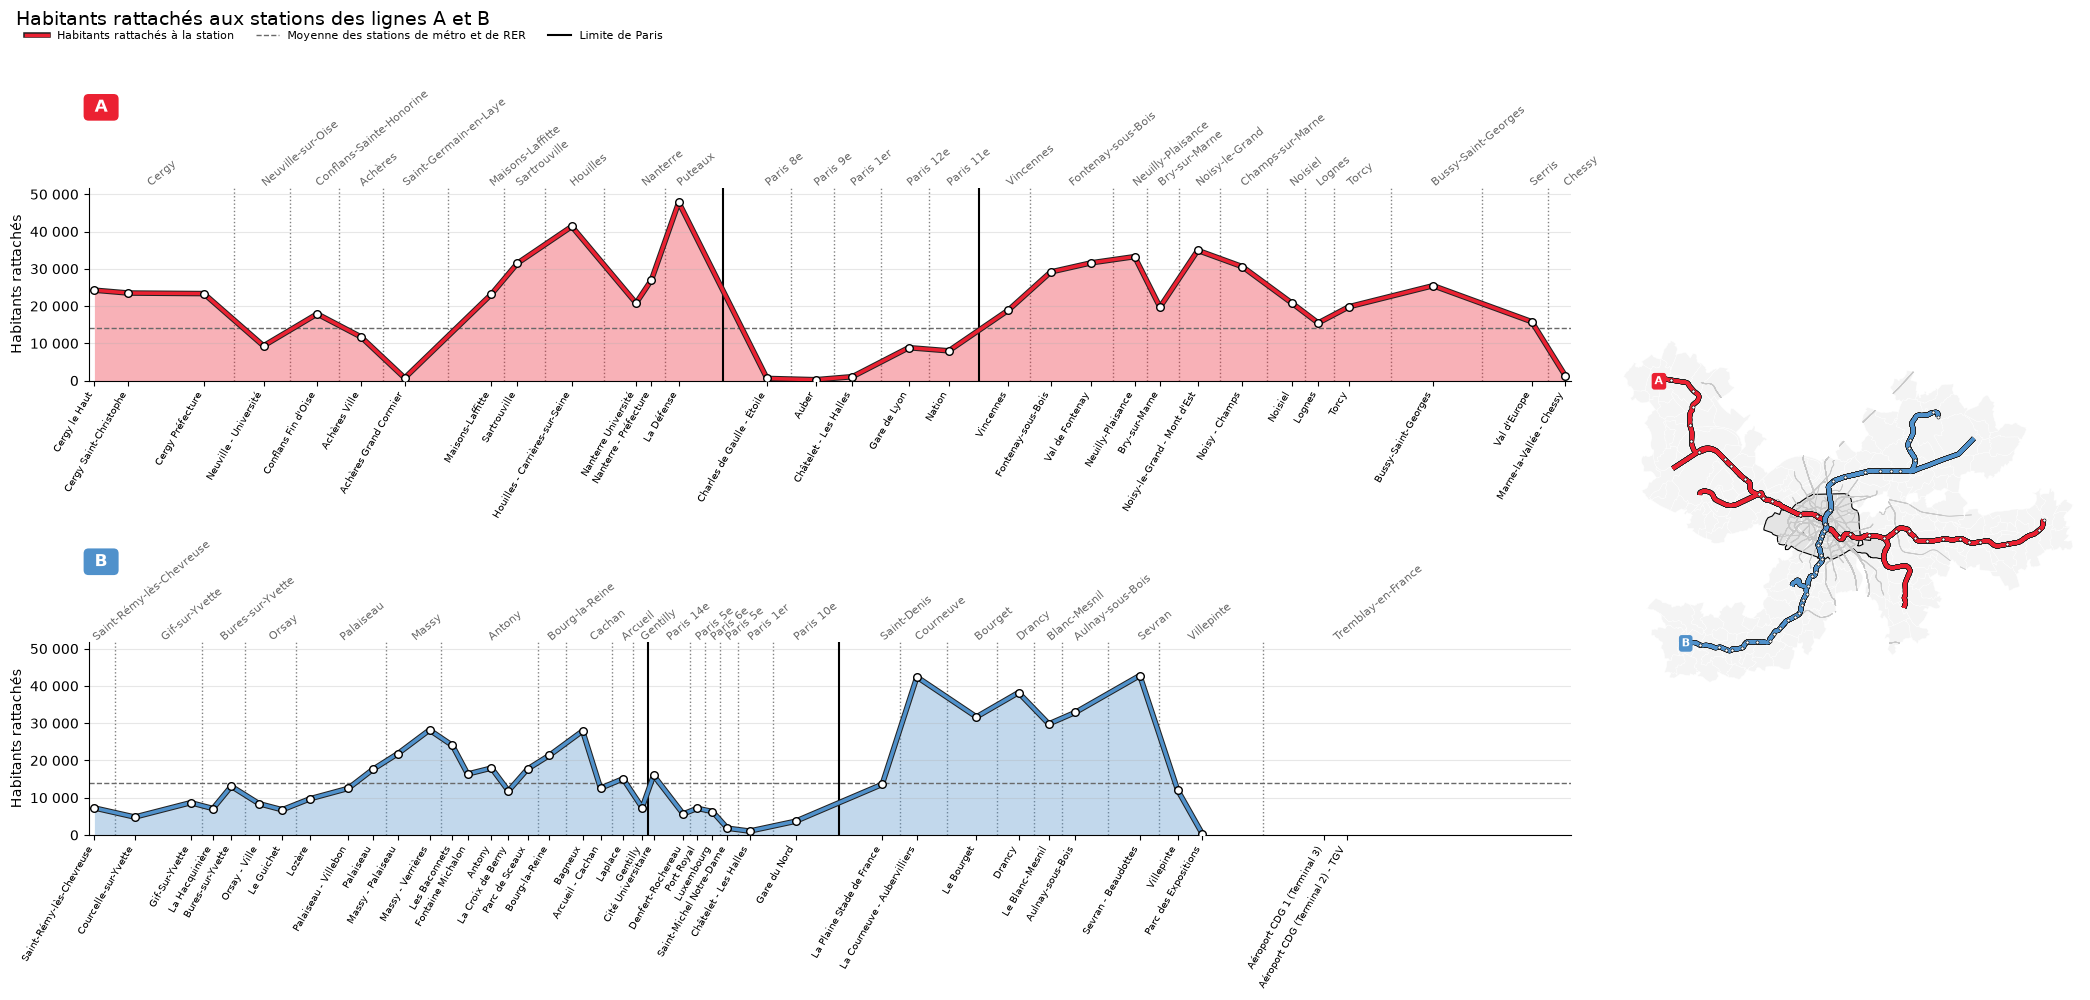

In [ ]:
axes = generer_montagnes_population(lignes_rer, df_nv, gpd_idfm, gpd_communes)
enregistrer_graphique(axes[0], "RER A et B : habitants par station")
plt.show()

## 5. Limites

- **Centre de Paris** : peu d'habitants vivent près des stations, et les stations sont si proches que chacune ne récupère que quelques carreaux (248 habitants pour Concorde, contre 48 000 pour La Défense). Les valeurs par station y sont fragiles ; les barres des carreaux le sont moins.
- **Lignes à branches** (13, RER A et B) : la montagne ne suit que la branche la plus longue (Saint-Denis pour la 13, Cergy → Chessy pour le A, Saint-Rémy → Roissy pour le B). Le plan montre toutes les branches, mais seules les stations de la branche suivie y sont marquées.
- **Stations en limite de commune** : chaque station est rattachée à la commune qui contient son point. Château de Vincennes tombe ainsi dans le 12e arrondissement (le bois de Vincennes fait partie de Paris).
- **Aéroport CDG** (RER B) : aucun habitant à moins de 1,5 km, donc pas de valeur pour ces deux stations. Et plus généralement : un carré sans habitant (la Seine, les parcs, les zones d'activité) n'apparaît pas du tout : ce sont les trous des montagnes.
- **RER dans Paris** : chaque habitant n'est rattaché qu'à sa station la plus proche, métro compris. Les gares du RER dans Paris (Auber, Châtelet - Les Halles…) ont donc très peu d'habitants rattachés : ils le sont aux stations de métro voisines.
